# ЧАСТЬ 2. Качество изображений (Василий).

### Подготовка данных для анализа качества изображений

In [1]:
import pandas as pd
import config

# Берем корень проекта из config.py
metadata_path = config.ROOT / "data" / "splits.csv"
df = pd.read_csv(metadata_path)


# исключаем дубликаты и ошибочные снимки, которые Виталий пометил как 'excluded'.
# reset_index(drop=True) нужен, чтобы после удаления строк индексы шли подряд (0, 1, 2...)
df = df[df['split'] != 'excluded'].reset_index(drop=True)

# Переименовал колонку 'path' на 'image_path', чтобы не пришлось менять остальной код.
df = df.rename(columns={'path': 'image_path'})

# Формируем полные (абсолютные) пути к картинкам, чтобы cv2 мог их открыть
df['image_path'] = [str(config.DATA_OCT / p) for p in df['image_path']]

print(f"Загружено строк: {len(df)}")
print("Пример пути:", df['image_path'].iloc[0])
df.head()






Загружено строк: 100082
Пример пути: /Users/vasilii/Desktop/project/data/raw/OCT/test/CNV/CNV-1032178-1.jpeg


,image_path,split,label,patient_id,reason
0,/Users/vasilii/Desktop/project/data/raw/OCT/te...,test,CNV,1032178,NaN
1,/Users/vasilii/Desktop/project/data/raw/OCT/te...,test,CNV,1034361,NaN
2,/Users/vasilii/Desktop/project/data/raw/OCT/te...,test,CNV,1034361,NaN
3,/Users/vasilii/Desktop/project/data/raw/OCT/te...,test,CNV,1052341,NaN
4,/Users/vasilii/Desktop/project/data/raw/OCT/te...,test,CNV,1106195,NaN



## Галерея по классам

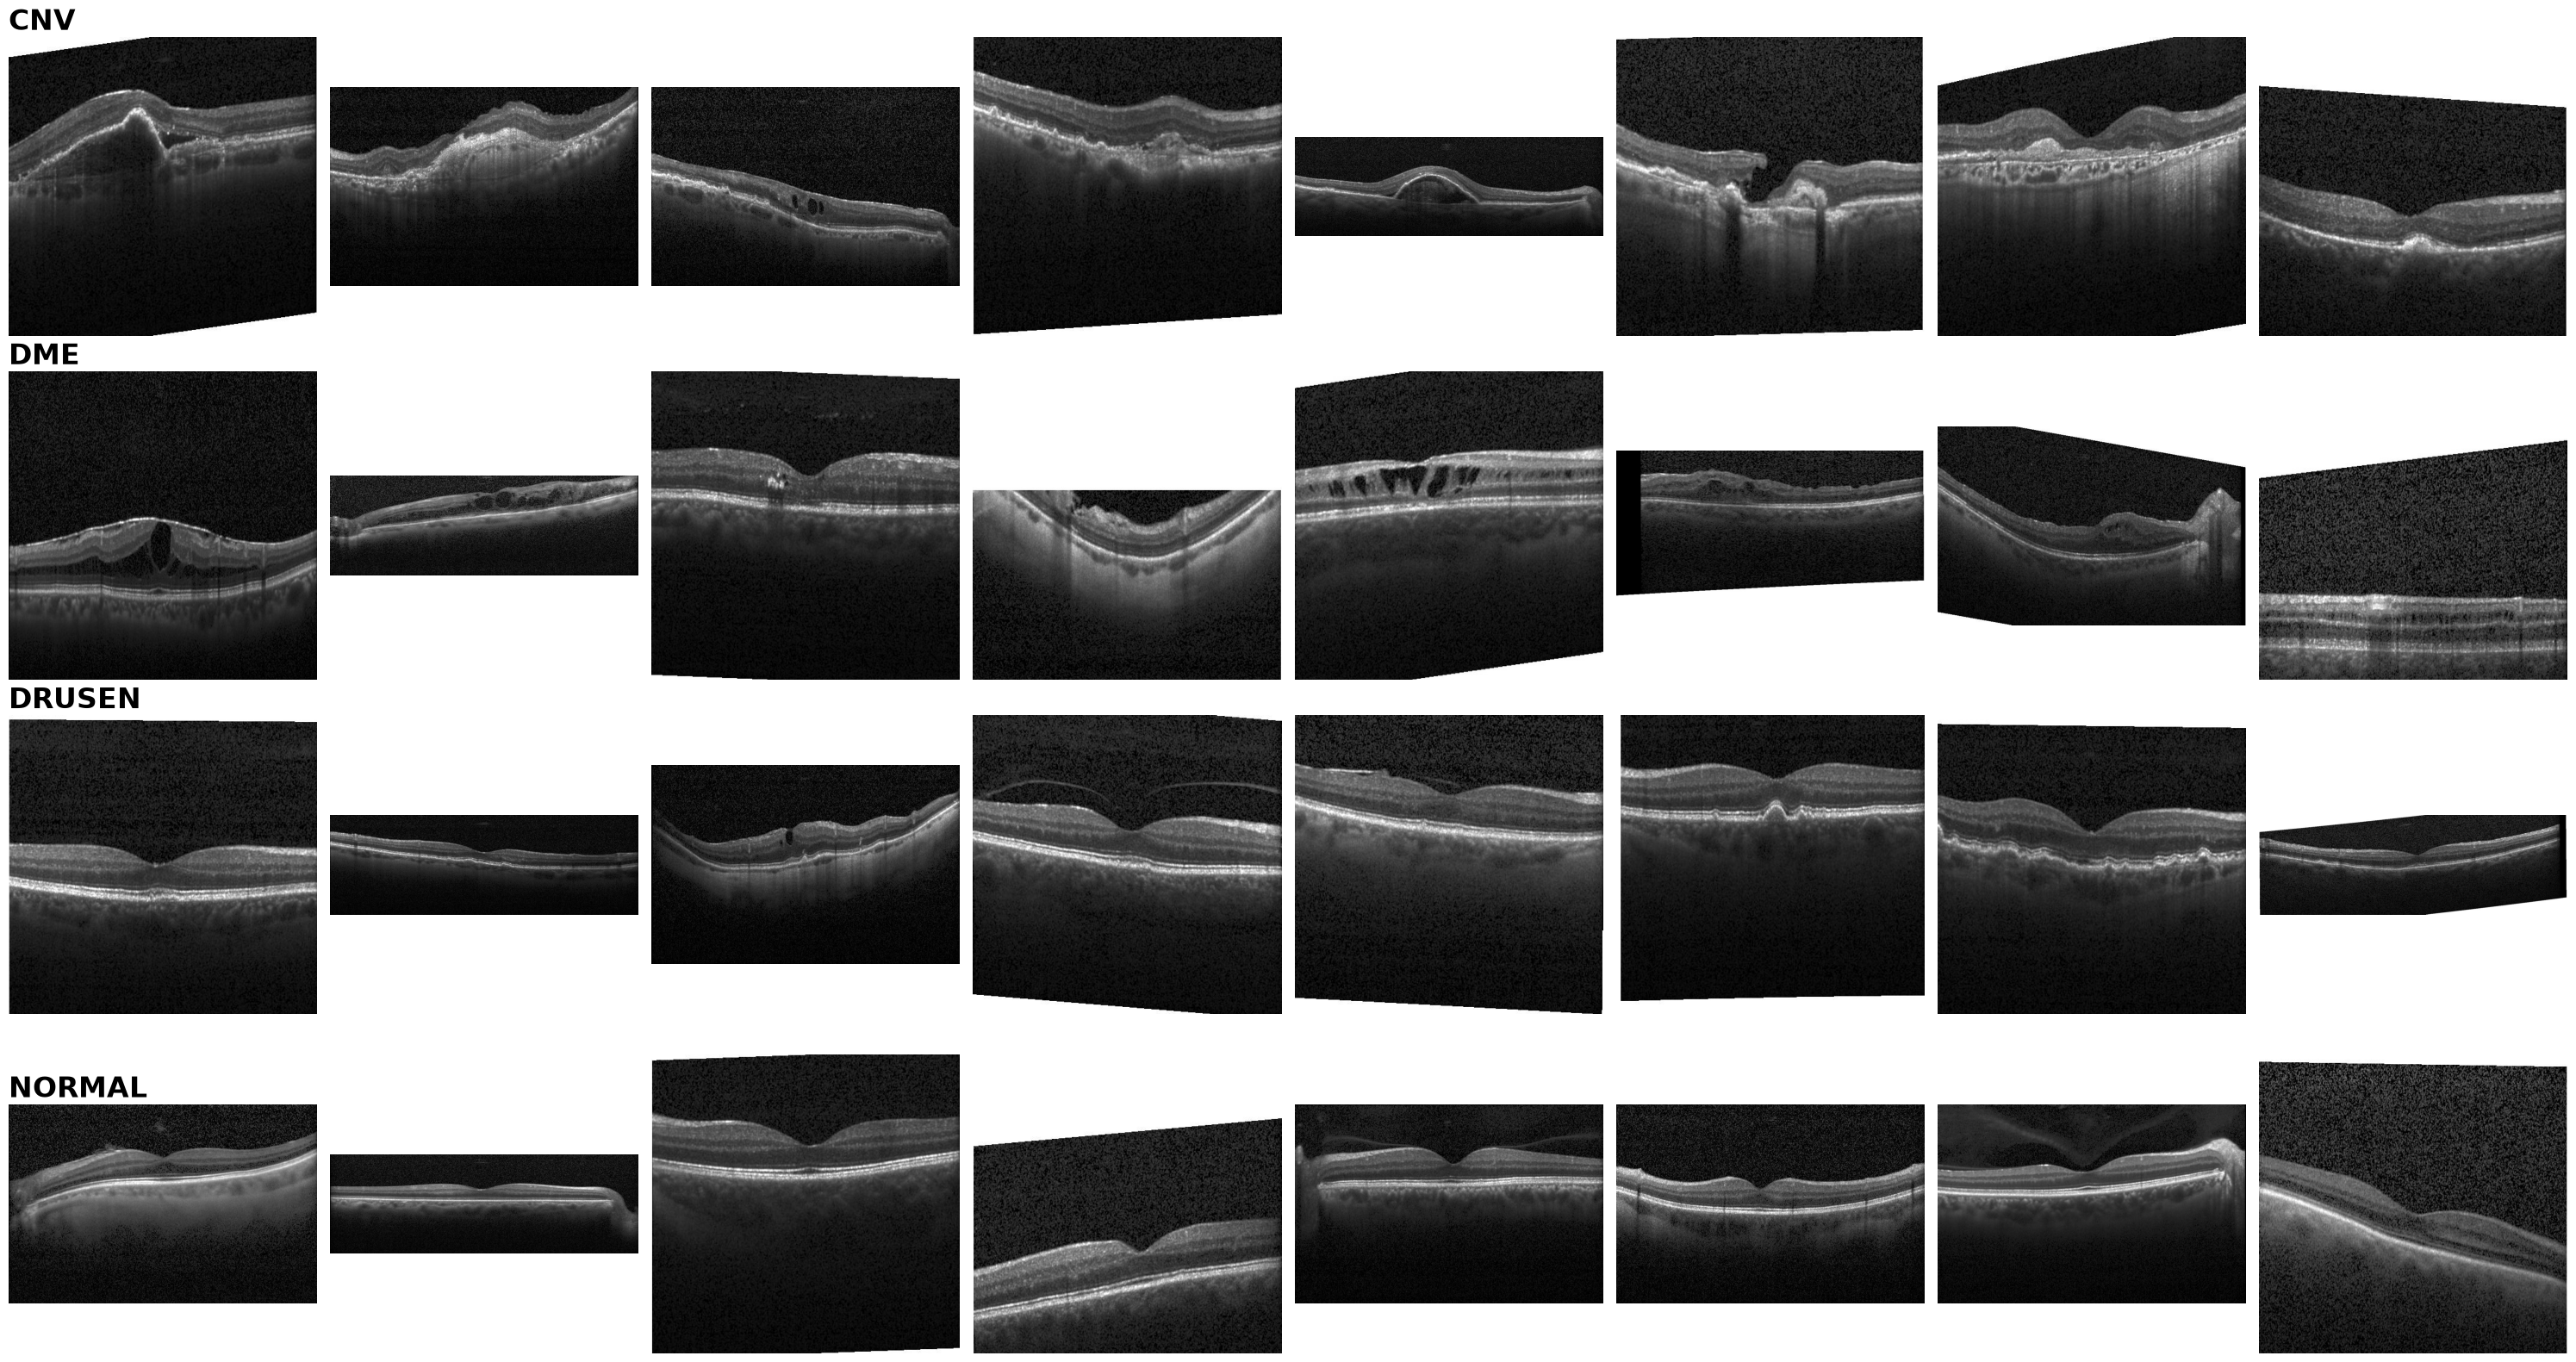

In [2]:
#Галерея примеров по классам. Выводится 4 класса по 8 случайных снимков.

import matplotlib.pyplot as plt 

classes = df['label'].unique()

fig, ax = plt.subplots(4, 8, figsize=(30, 16))

#Идем по каждому классу, i - номер строки, clas - название класса
for i, clas in enumerate(classes):
    #оставляем только строки, которые совпадают с текущим классом и берем 8 случайных снимков
    paths = df[df['label'] == clas].sample(8)['image_path'] 

# Проходимся по 8 картинкам: n - номер колонки, path - путь к файлу
    for n, path in enumerate(paths):
        img = plt.imread(path)

        ax[i, n].imshow(img, cmap ='gray')
        ax[i, n].axis('off')

#Подписываем класс только для первой картинки в строке
        if n == 0:
                ax[i, n].set_title(clas, fontweight='bold', fontsize=24, loc='left')

plt.tight_layout()
plt.show()  
    

               



### На представленных снимках в галереи можем отчетливо обозначить каждый класс:

1. **CNV** (хориоидальная неоваскуляризация) - Деформированная и неупорядоченная структура сетчатки, полный хаос.

2. **DME** (диабетический макулярный отек) - Сетчатка разбухшая, в центральных слоях видим темные кисты, которые могут быть от маленьких до больших размером. 

3. **DRUSEN** (друзы) - под пигментным эпителием(это самая яркая линия на картинке) в некоторых отрезках видны бугорки, который выпячивают этот слой сетчатки.

4. **NORMAL** - ровные, четко различимые слои сетчатки глаза.





## Битые файлы

In [3]:
#Смотрим, есть ли битые файлы
import cv2

widths = []
heights = []
channels = []
broken_files = []

#проходим по каждому пути 
for p in df['image_path']: 
    try:
        img = cv2.imread(p) #пытаемся открыть картинку с диска

        if img is None:
           raise ValueError("Битый файл") #если картинка не открылась, вызывваем ошибку

        h, w = img.shape[:2] #если картинка открылась, берем высоту и ширину
        
        if len(img.shape) == 2: #если в размерах картинки 2 числа(высота и ширина)
            c = 1 # 1 канал - черно-белая картинка
        else:
            c = img.shape[2] #берется 3 число(количество каналов)

        widths.append(w)
        heights.append(h)
        channels.append(c)
        broken_files.append(False)

    except Exception:     
       widths.append(None)
       heights.append(None)
       channels.append(None)
       broken_files.append(True)


#добавляем новые колонки в таблицу df
df['width'] = widths
df['height'] = heights
df['channels'] = channels
df['broken_files'] = broken_files

print(f"Битых файлов: {df['broken_files'].sum()}")

Битых файлов: 0






## Гистограммы: количество каналов, ширина и высота снимков, распределение пропорций, вывод снимков по их соотношениям


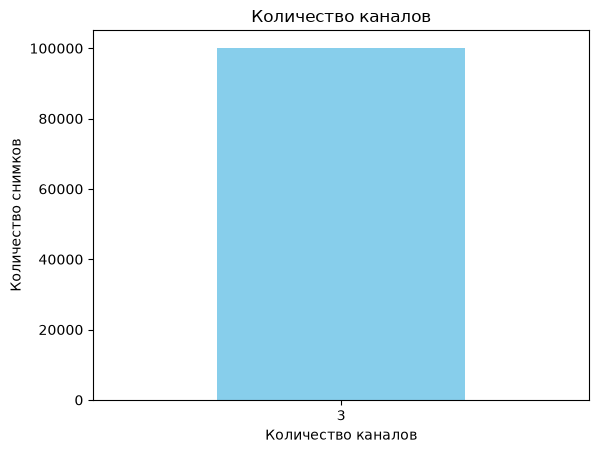

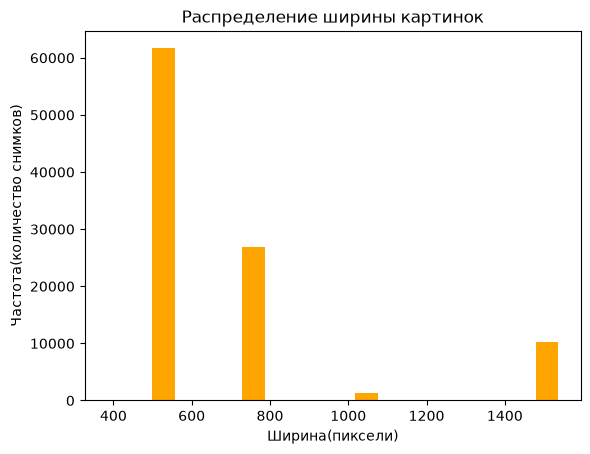

width
512     61636
768     26863
1536    10272
1024     1288
384        21
642         1
900         1
Name: count, dtype: int64


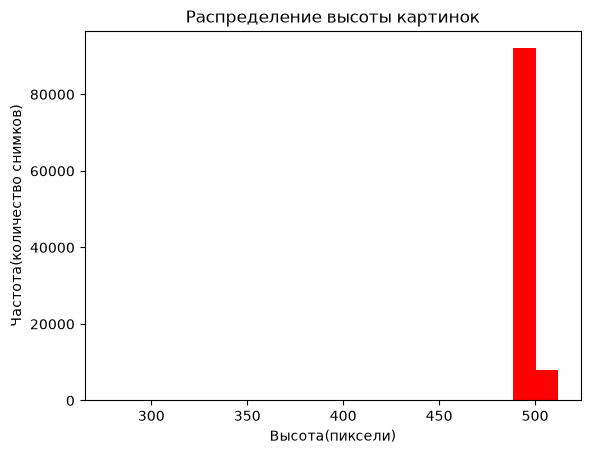

height
496    91981
512     8099
277        1
455        1
Name: count, dtype: int64


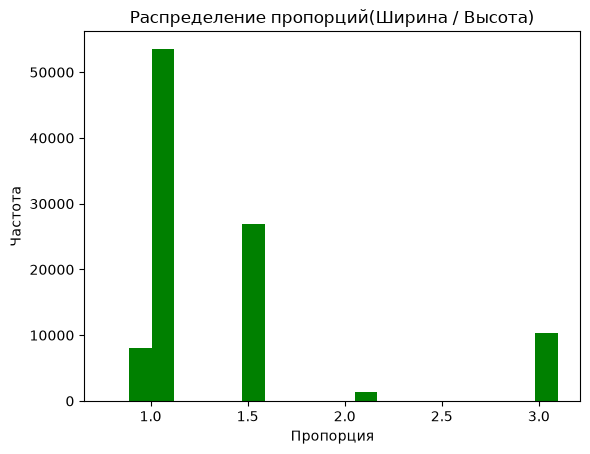

width  height
512    496       53537
768    496       26863
1536   496       10272
512    512        8099
1024   496        1288
384    496          21
642    277           1
900    455           1
dtype: int64


In [4]:
#Строим графики количества каналов, ширины, высоты, распределение пропорций. 
import matplotlib.pyplot as plt

df['ratio'] = df['width'] / df['height']



df['channels'].value_counts().plot(kind = 'bar', color ='skyblue')
plt.title('Количество каналов')
plt.xlabel('Количество каналов')
plt.ylabel('Количество снимков')
plt.xticks(rotation=0)
plt.show()

df['width'].plot(kind = 'hist', bins = 20, color ='orange')
plt.title('Распределение ширины картинок')
plt.xlabel('Ширина(пиксели)')
plt.ylabel('Частота(количество снимков)')
plt.show()
print(df['width'].value_counts().head(10))

df['height'].plot(kind='hist', bins=20, color ='red')
plt.title('Распределение высоты картинок')
plt.xlabel('Высота(пиксели)')
plt.ylabel('Частота(количество снимков)')
plt.show()
print(df['height'].value_counts().head(10))

df['ratio'].plot(kind='hist', bins=20, color = 'green')
plt.title('Распределение пропорций(Ширина / Высота)')
plt.xlabel('Пропорция')
plt.ylabel('Частота')
plt.show()

# выводим количество снимков по уникальным разрешениям
# df.groupby - собирает картинки вместе с одинаковыми разрешениями, size() - считает их
sizec_count = df.groupby(['width', 'height']).size().sort_values(ascending=False)
print(sizec_count)




### Вывод:

* Всего 8 уникальных разрешений снимков. Наиболее частые: **512x496, 768x496, 1536x496, 512x512**. 

* пропорции картинок различаются, надо привести к одному размеру, но обязательно сохранить анатомические пропорции на картинках.

* У меня на графике на всех картинках 3 канала, у Виталия 1.  Я использовал библиотеку OpenCV, которая, если не указать ограничение, будет считывать 3 канала, даже если картинка черно-белая.




## Подозрительные снимки

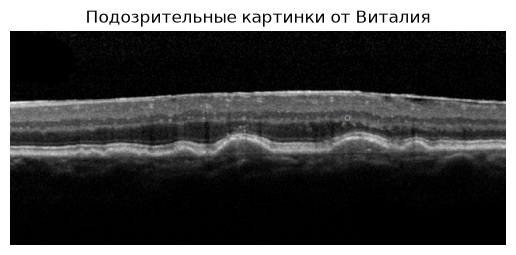

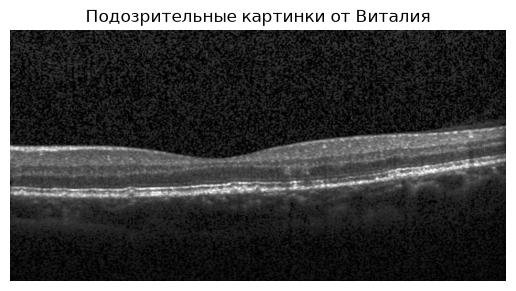

In [5]:
#Выводим подозрительные картинки, которые подметил Виталий.
import matplotlib.pyplot as plt

#берем по 2 ширинам, которые встречаются тольку у этих картинок
weird_imgs = df[(df['width'] == 642) | (df['width'] == 900)]

for p in weird_imgs['image_path']: #проходимся по этим путям и выводим картинки
    img = plt.imread(p)
    plt.imshow(img, cmap='gray')
    plt.title('Подозрительные картинки от Виталия')
    plt.axis('off')
    plt.show()

### Вывод:

Эти картинки схожи с другими.  Возможно, из-за необычного размера и 3 каналов, эти картинки были взяты уже из какого-то источника, их могли просто вырезать и сохранить.

* 1 картинка: похоже что обрезана как-то так, что центральной ямки не видно, но друзы есть и они отчетливы.

* 2 картинка: кажется, что бока обрезаны и видна большая центральная ямка. Друзы сложновато здесь различить. Возможно, что сам по себе класс друзы неоднороден.








## Графики яркости, контраста и средний снимок для каждого класса.

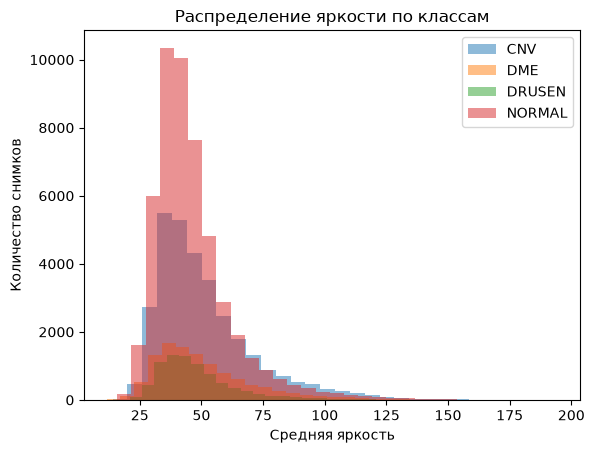

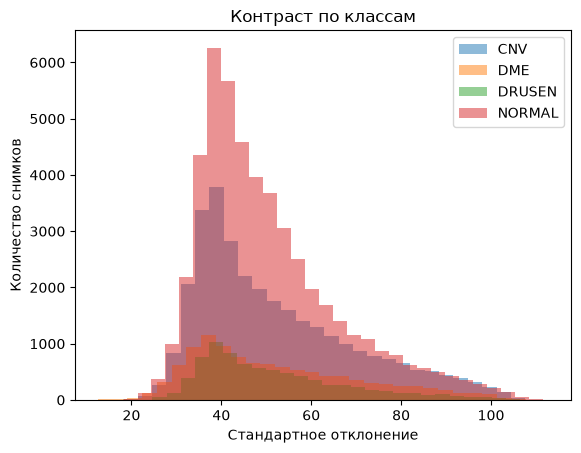

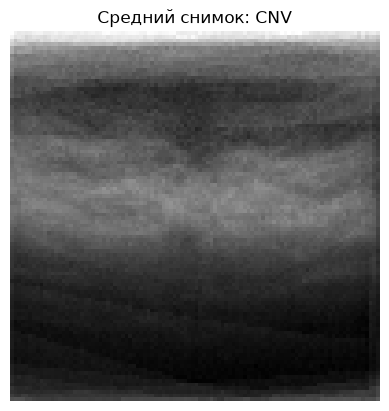

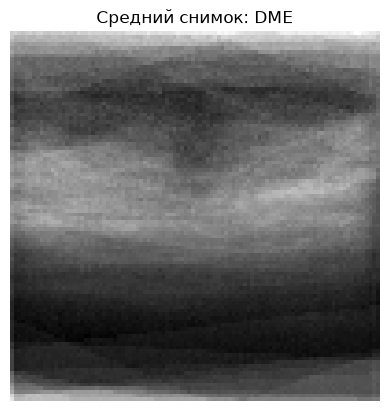

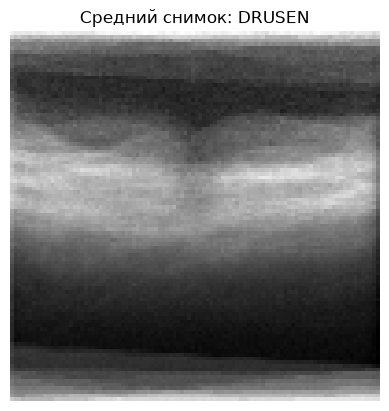

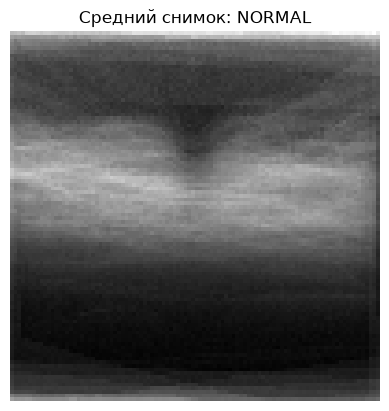

In [6]:
#Выводим графики яркости, контраста и средний снимок для каждого класса.
import cv2
import matplotlib.pyplot as plt
import numpy as np

bright = []
contrast = []

for b in df['image_path']:
    # b - путь к картинке, 0 - просим функцию прочитать картинку только в 1 канале
    img = cv2.imread(b, 0) 
    bright.append(img.mean())
    contrast.append(img.std())

df['bright'] = bright
df['contrast'] = contrast

#идем по каждому классу
for cls in df['label'].unique():
    subset = df[df['label'] == cls]  # оставляем строки текущего класса, берем все снимки класса
    plt.hist(subset['bright'], bins = 30, alpha=0.5, label=cls)

plt.title('Распределение яркости по классам')
plt.xlabel('Средняя яркость')
plt.ylabel('Количество снимков')
plt.legend()
plt.show()

for cls in df['label'].unique():
    subset = df[df['label'] == cls]
    plt.hist(subset['contrast'], bins=30, alpha=0.5, label=cls)

plt.title('Контраст по классам')
plt.xlabel('Стандартное отклонение')
plt.ylabel('Количество снимков')
plt.legend()
plt.show()

#Средний снимок
for cl in df['label'].unique():
    paths = df[df['label'] == cl].sample(50)['image_path']  # строки тек. класса, 50 случайных

    #проходимся по каждой из 50 картинок в ч/б и сжимаем 100 на 100 все в одинаковый размер.
    #Одинаковый размер нужен для усреднения
    imgs = [cv2.resize(cv2.imread(p, 0), (100, 100)) for p in paths]

    mean_img = np.mean(imgs, axis = 0)

    plt.imshow(mean_img, cmap = 'gray')
    plt.title(f'Средний снимок: {cl}')
    plt.axis('off')
    plt.show()

### Вывод: 
* Распределение яркости и контраста по классам перекрывают друг друга.

* Средний снимок изображения по каждому классу  должен демонстрировать визуальные различия между ними, но по факту это сложно сделать, так как те или иные патологические признаки, характерные для того или иного заболевания, неоднородны и могут распологаться в разных участках сетчатки.




## Количество выбросов

In [25]:
#Условия, по которым посчитаем количество выбросов

darker = df['bright']<20
brighter = df['bright']>130
wider = df['width'] > 1024

out = df[darker|brighter|wider]

out.to_csv('outliers.csv', index=False)
print(f'Выбросы: {len(out)}')

Выбросы: 10808







## Просмотр пересвеченных и затемненных снимков

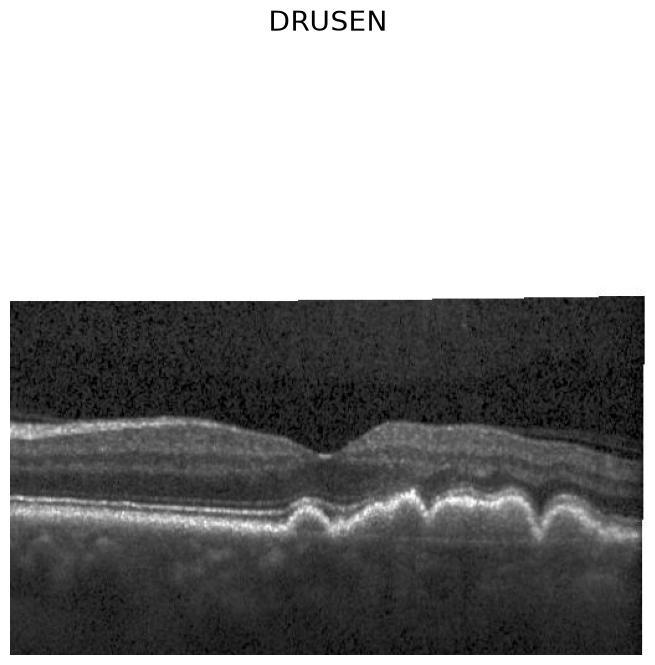

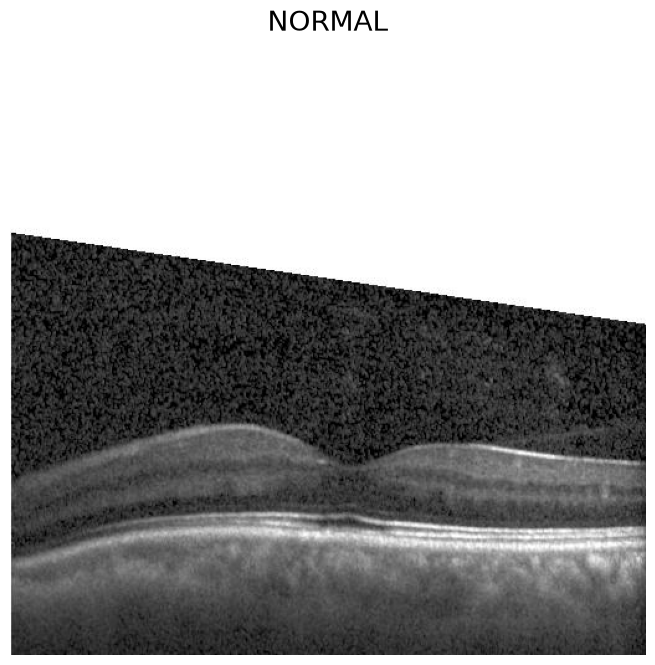

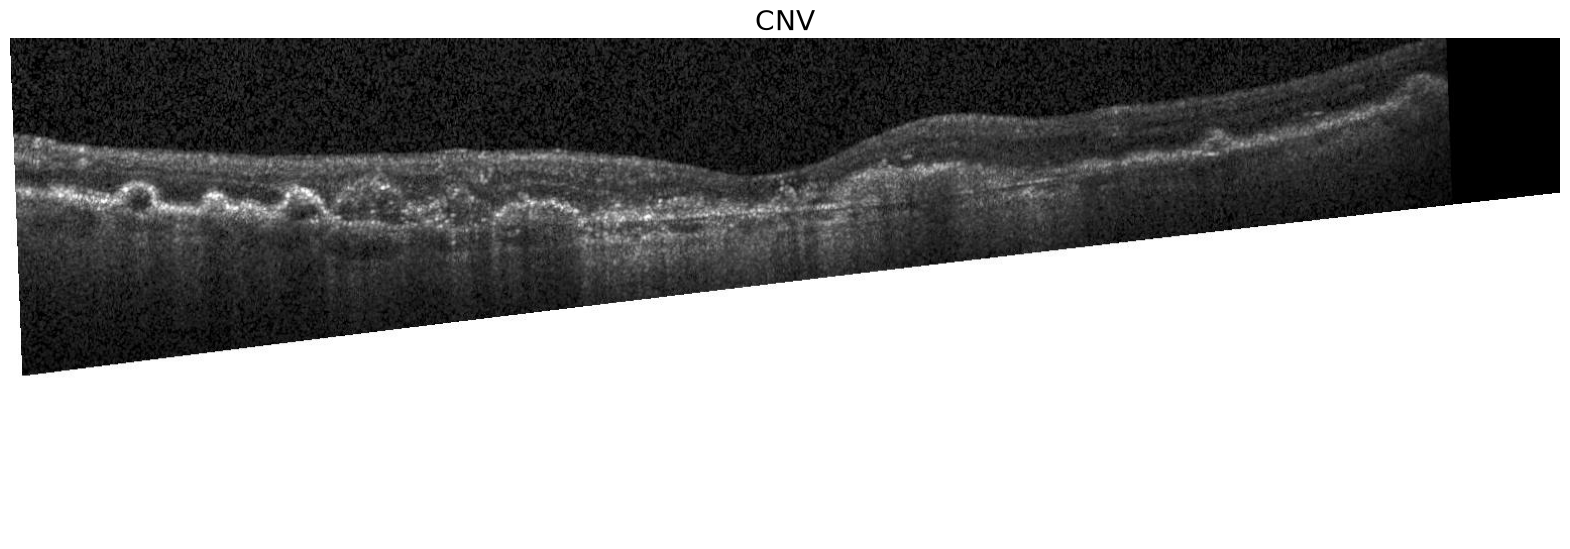

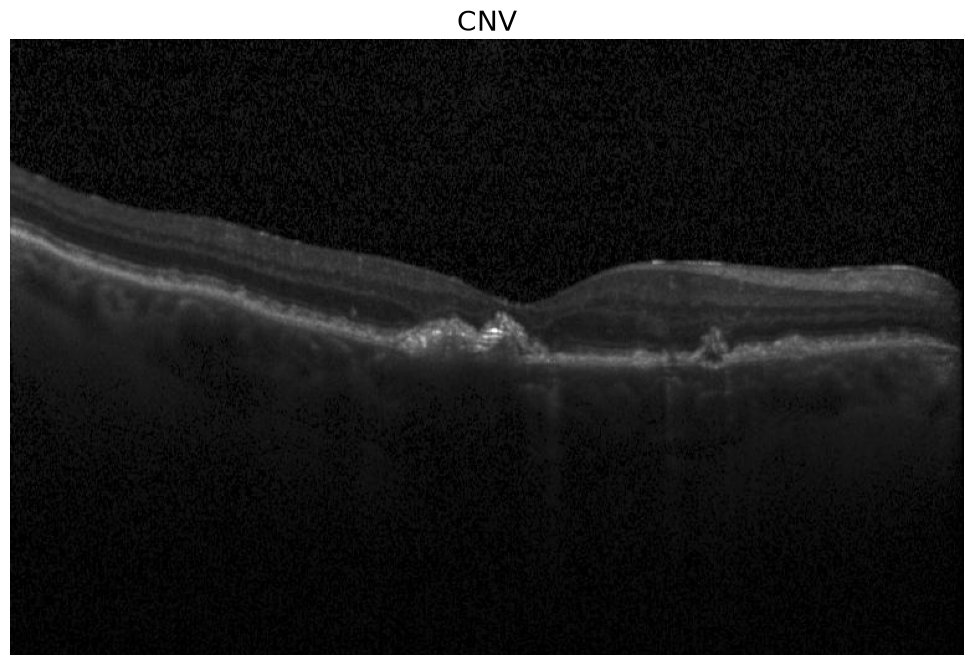

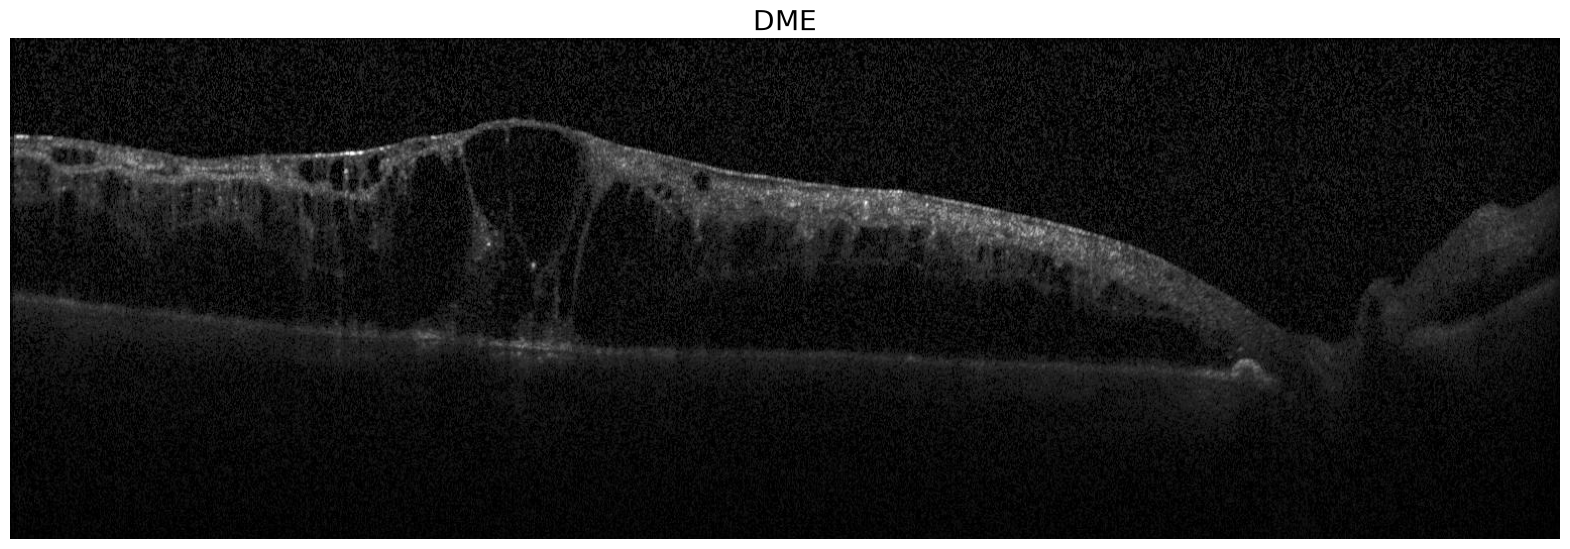

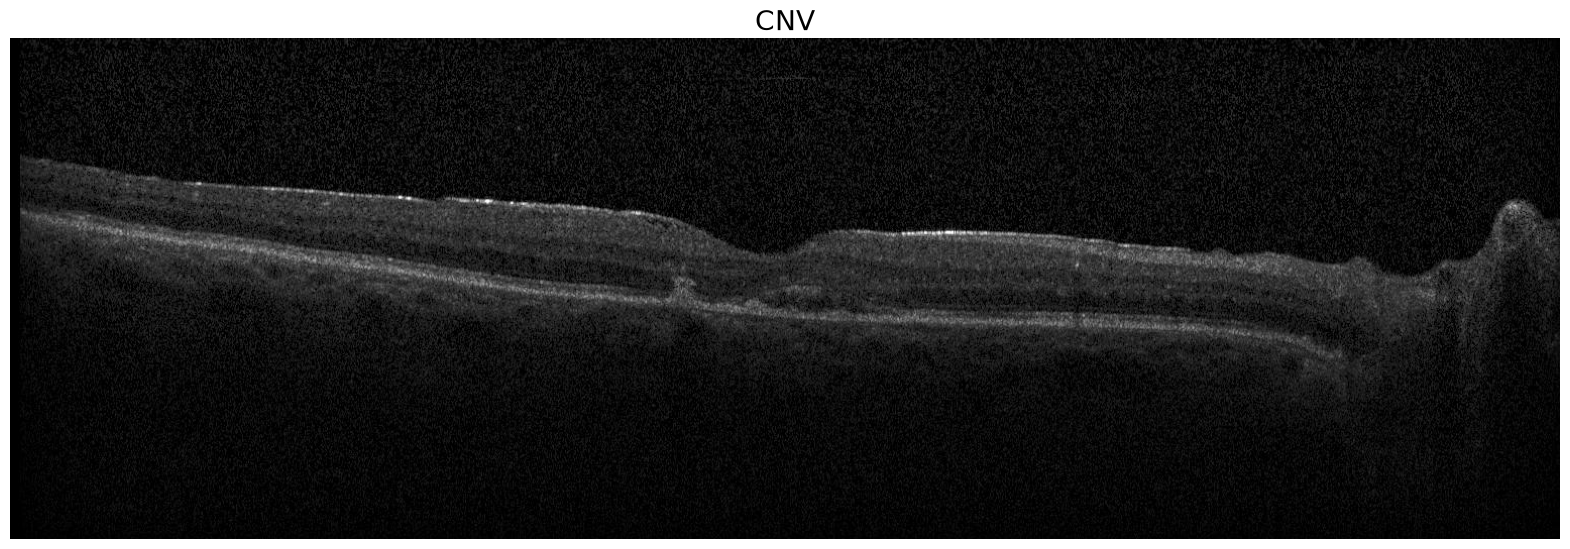

In [18]:
#Ручной просмотр выбросов
import pandas as pd
import matplotlib.pyplot as plt

outliers_df = pd.read_csv('outliers.csv')

#смотрим пересвеченные снимки
brighter_outliers = outliers_df[outliers_df['bright'] > 130].sample(3)



for i in range(3):

    row = brighter_outliers.iloc[i]
    img = plt.imread(row['image_path'])
    plt.figure(figsize=(20,8))
    plt.imshow(img, cmap='gray')
    plt.title(row['label'], fontsize=20)
    plt.axis('off')
    plt.show()

#смотрим наиболее затемненные снимки
darker_outliers = outliers_df[outliers_df['bright'] < 20].sample(3)


for i in range(3):

    row = darker_outliers.iloc[i]
    img = plt.imread(row['image_path'])
    plt.figure(figsize=(20,8))
    plt.imshow(img, cmap='gray')
    plt.title(row['label'], fontsize=20)
    plt.axis('off')
    plt.show()    

### Вывод:

* В ходе просмотра снимков ошибок в разметке не выявил, даже с такой яркостью на выбросах можно определить класс.

* Однако, на темных и ярких снимках заметна зернистоть, иногда крайне значительная.
 



# mean и std яркости (весь датасет)

In [19]:
#Считаем mean и std яркости
mean_val = df['bright'].mean()/255.0
std_val = df['bright'].std()/255.0

print(f'mean: {mean_val.round(4)}')
print(f'std: {std_val.round(4)}')


mean: 0.1908
std: 0.0727


### Примечание: 
Эти усредненные значения по всему датасету по яркости. Для обучения модели лучше использовать следущий блок расчетов.




## Расчет mean и std попиксельно для train

In [20]:
import cv2
import numpy as np

# берем train
train_path = df[df['split'] == 'train']['image_path'].tolist()

# переменные для подсчета
suma_pixels = 0
suma_sq_pixels = 0
count_pixels = 0

# идем по каждой картинке
for path in train_path:
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is not None:  #  защита на случай битого файла (хотя здесь таких нет) или неверного пути
        img = img / 255.0

        # Складываем пиксели и квадраты пикселей
        suma_pixels += img.sum()
        suma_sq_pixels += (img ** 2).sum()
        count_pixels += img.size

#Расчет mean и std 
mean_p = suma_pixels / count_pixels
variance = (suma_sq_pixels / count_pixels) - (mean_p ** 2)  # здесь считаем дисперсию 
std_p = np.sqrt(variance)

print(f'mean: {mean_p.round(4)}')
print(f'std: {std_p.round(4)}')


mean: 0.18
std: 0.2138


### Общий вывод по части Василия:
* Анализ датасета проведен уже по очищенной версии Виталия с исключенными снимками (дубликаты).

1. Датасет довольно неоднороден, встречаются разные размеры изображений, но наиболее часто 512x496, 768x496. Пропорции снимков тоже сильно различаются, но чаще ближе к 1 или к 1.5. 

* Однако есть и длинные снимки с пропорцией равным 3 (их около 10000).
Cледовательно, снимки надо привести к одному размеру, при этом, очень важно, не исказить их анатомические пропорции на картинках.

* Рекомендовано привести к 224x224(однако, может лучше подойдет 256x256 из-за мелких патологических деталей на снимках). Так же надо использовать Padding(добавление черных полей), чтобы сохранить анатомические пропорции.

* В датасете встречаются также снимки с разной степенью приближения, поэтому надо будет научить модель распознавать патологию на таких изображениях.

* Также встречаются криво обрезанные и наклонные изображения. Рекомендуется либо Deskew (выравнивание), либо CenterCrop (вырезает и оставляет центр). Однако могут встречаться снимки с сильным приближением, которые еще и наклонены. Тогда, например, лучше использовать аугментацию вращения (RandomRotation) и масштабирования (RandomResizedCrop).

2. Снимки через библиотеку OpenCV считываются как 3-х канальные, несмотря на то, что снимки ч/б. У Виталия в метаданных указан 1 канал.

2. Распределения яркости и контраста по классам сильно перекрывают друг друга, значит, модель не сможет опираться на эти признаки.

3. Битых файлов нет. 

4. При ручном просмотре некоторых снимков нарушения разметки не выявлено. 

5. В выбросы попало 10808 (10,8%) снимков, которые наиболее темные, пересвеченные, широкие. На них можно распознать класс, однако может иногда мешать чрезмерная зернистость(спекл шум). Ее надо будет убирать (например, медианный фильтр (cv2.medianBlur)).

6. mean = 0.18, std = 0.2138 попиксельно для train. 






